# 2 · A two-scale extrapolator

The first trained model. It takes the client's two frames, `previous` and `current`, and adds
a correction to `current`:

- **It starts as repeat.** Its last convolution starts at zero, so untrained it shows the
  newest frame again - the best of notebook 1's methods that can be exported, and already
  close to perfect wherever nothing changes. Training can only move it from there.
- **It works at a quarter of the resolution**, where a few 3x3 convolutions reach far
  enough to follow a scroll: notebook 1 found 95% of them move under 16 px a frame, and
  continuing the motion worth +5 dB on the changed samples. A search over offsets cannot
  be exported; a network has to learn the motion instead.
- **It is built for the browser**: `Conv`, `LeakyRelu`, `Concat`, `DepthToSpace` and `Add`
  only, and no convolution at full resolution with 3 output channels.

Beside it, a **control** at the same cost with no downsampling. If it does as well, the
quarter-resolution path is not needed.

Steps:

1. **Data** - the runs at a halo of 8, and the validation samples at 8 and at the client's 4.
2. **Model** - the two networks, checked to start as repeat.
3. **Speed** - in torch, and the ONNX graph at the client's tile.
4. **Train** - both, against repeat and notebook 1's tile shift.
5. **Results** - by group, by kind of source and by halo, and what it looks like.
6. **Save** and **export**.

Needs: `00_data_preprocess.ipynb`. Results: `summary.md`, "The two-scale model".
Writes `checkpoints/extrapolate_twoscale.pt`.

In [1]:
"""Settings."""

import matplotlib.pyplot as plt
import numpy as np
import torch

from helpers import metrics, models, runs, speed, training, webexport
from helpers.training import DATA_DIR, DEVICE

CHECKPOINT = training.CHECKPOINT_DIR / "extrapolate_twoscale.pt"
RUN_DIR = training.CHECKPOINT_DIR / "twoscale_runs"     # each training, resumable

# The networks (see "2. Model")
WIDTHS = (16, 32)            # channels at 1/2 and 1/4 of the resolution
BLOCKS = 3                   # 3x3 convolutions at 1/4
CONTROL_WIDTH = 8            # the control: channels at full resolution...
CONTROL_BLOCKS = 4           # ...and 3x3 convolutions - about the same operations a pixel

HALO = 8                     # trained and scored with this much context; also scored at the client's 4
CONTEXT, AHEAD = 2, 1        # the client's contract
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
# A safety limit: training stops once it has converged. Set it to 2 for a smoke test that
# only shows every cell runs; a run carries on from its checkpoint when it is raised again.
MAX_EPOCHS = 500
# Write the graph into dist/frame_gen_extra/ only once it is a real model: a smoke test's
# goes to checkpoints/ instead
PUBLISH = False
SEED = 0

BENCH_SIZES = [(640, 360), (960, 540), (1280, 720), (1920, 1080)]   # stream frames
NAME = "twoscale_16-32x3"

training.seed_everything(SEED)

## 1. Data

The training loader picks a random newest frame of each run and flips half of them; the
validation samples are fixed, as in notebook 1. Every score is over the 64 px core, so
the scores at a halo of 8 and of 4 are of the same pixels. Only the context differs.

In [2]:
manifest = training.load_manifest()
training.describe(manifest)
train_loader = training.loader(DATA_DIR, manifest, BATCH_SIZE, CONTEXT, AHEAD, halo=HALO)

validation = {}
for halo in sorted({HALO, webexport.TILE_HALO}):
    inputs, targets = runs.load(DATA_DIR, "val", manifest, CONTEXT, AHEAD, halo=halo)
    masks = runs.groups(manifest, "val", inputs[:, -1], targets, halo)
    validation[halo] = (inputs, targets, masks)
KINDS = [kind for kind in ("page", "desktop", "photo", "video", "cursor") if kind in masks]
for halo, (_, _, masks) in validation.items():
    for kind in KINDS:
        masks[f"{kind}, changed"] = masks[kind] & masks["changed"]

inputs, targets, masks = validation[HALO]
STEP = runs.received_every(manifest)   # received frames N-2 and N in, N+1 out
FRACTION = AHEAD / STEP                # for the static baselines: carry half the motion
print("val    ", inputs.shape, "->", targets.shape)
print("samples", {name: int(mask.sum()) for name, mask in masks.items() if "," not in name})

device  cuda NVIDIA GeForce RTX 3090
stream  x2 down from a 1280x720 window, 60 fps
run     96 px (64 px + a halo of 16), 8 frames each
stream  every 2th frame received - the inputs are frames N-2 and N, the target N+1 (2x frame generation)
train  11445 runs from 748 sources


val     (1677, 2, 80, 80, 3) -> (1677, 80, 80, 3)
samples {'all': 1677, 'changed': 749, 'unchanged': 928, 'cursor': 164, 'page': 686, 'desktop': 431, 'video': 160, 'photo': 400}


## 2. Model

    previous, current --> Concat (6 ch) --> conv 3x3 /2 -> 16 ch ------------------------+ (1/2)
                                         --> conv 3x3 /2 -> 32 ch                        |  (1/4)
                                         --> 3 x [conv 3x3 32 -> 32]                     |  (1/4)
                                         --> DepthToSpace -> 8 ch --> Concat <-----------+  (1/2)
                                         --> conv 3x3 24 -> 12 --> DepthToSpace -> 3 ch       (full)
    current ------------------------------------------------------------------------> Add --> output

LeakyReLU after every convolution but the last, which starts at zero. The control is
`Plain`: a 3x3 stem to 8 channels, four 3x3 convolutions, and a 3x3 to the 3 colours, all
at full resolution.

**Reach.** At a quarter of the resolution every 3x3 convolution reaches 4 more pixels: the
two-scale network sees about ±20 px around a pixel, the control ±6. Both reach past the
halo, so the edge of the core is made partly from the zeros a convolution pads with - as on
the client, whose tiles are cut the same way.

**Size.** Every side of the input must be a multiple of 4: the client's 328x188 tile is,
and so are the 72, 80 and 96 px of the validation samples at a halo of 4, 8 and 16.

**What is learned, and what is not.** Every weight of both networks is learned - fitted by
Adam to the training runs under L1 in Y'CbCr (the next cell counts them) - and nothing else
is given to them. There is no search, no offset and no warp: the network sees the two frames
side by side and has to *draw* N+1 as a correction added to N. To move a line of text 6 px
it has to learn to erase it where it was and paint it where it goes, from what 3x3
convolutions see. The bar beside it - repeat and notebook 1's shift - learns nothing.

In [3]:
model = models.TwoScale(WIDTHS, BLOCKS).to(DEVICE)
control = models.Plain(CONTROL_WIDTH, CONTROL_BLOCKS).to(DEVICE)
for name, network in (("two-scale", model), ("control", control)):
    parameters = sum(p.numel() for p in network.parameters())
    print(f"{name:10} {parameters:7,} parameters, {speed.operations_per_pixel(network):6,.0f} operations a pixel")
print(model)

two-scale   35,868 parameters,  5,775 operations a pixel
control      2,995 parameters,  5,947 operations a pixel
TwoScale(
  (down): ModuleList(
    (0): Sequential(
      (0): Conv2d(6, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): LeakyReLU(negative_slope=0.1)
    )
    (1): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): LeakyReLU(negative_slope=0.1)
    )
  )
  (body): Sequential(
    (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.1)
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): LeakyReLU(negative_slope=0.1)
    (4): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): LeakyReLU(negative_slope=0.1)
  )
  (up): ModuleList(
    (0): Conv2d(24, 12, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (shuffle): PixelShuffle(upscale_factor=2)
)


In [4]:
"""Before training: both must score exactly like repeat."""

repeat = training.evaluate(models.Repeat(), inputs, targets, masks, trim=HALO)
for name, network in (("two-scale", model), ("control", control)):
    start = training.evaluate(network, inputs, targets, masks, trim=HALO)
    assert abs(start["all"]["rgb"] - repeat["all"]["rgb"]) < 1e-6, f"the {name} model should start as repeat"
print("both start as repeat:", f"{repeat['changed']['ssim']:.4f} SSIM-Y, {repeat['changed']['wpsnr']:.2f} dB on the changed samples")

both start as repeat: 0.7040 SSIM-Y, 25.69 dB on the changed samples


## 3. Speed

Speed depends on the network's shape, not its weights, so it is checked before training.
First in torch on this computer's GPU, one stream frame at a time. Then as the ONNX graph
the client would run - one 328x188 tile, on the desktop CPU, which is not the browser but
does show what the graph is made of. The browser's number comes from the benchmark page,
which does not list two-input models yet.

In [5]:
"""torch, one frame at a time; and the graph at the client's tile."""

print(f"{'frame':>11}{'two-scale':>12}{'control':>12}   fits")
with torch.no_grad():
    for width, height in BENCH_SIZES:
        previous, current = torch.rand(2, 1, 3, height, width, device=DEVICE)
        ms = {name: speed.time_ms(lambda n=network: n.eval()(previous, current), seconds=0.5)
              for name, network in (("two-scale", model), ("control", control))}
        print(f"{f'{width}x{height}':>11}{ms['two-scale']:12.2f}{ms['control']:12.2f}   {speed.frame_budget(ms['two-scale'])}")
print("ms per frame")

step_h, step_w = webexport.TILE_STEP
for name, network in (("two-scale", model), ("control", control)):
    # into checkpoints/, not dist/: these are untrained
    info = webexport.export(network, f"speed_check_{name}.onnx", webexport.TILE_INPUT,
                            models_dir=training.CHECKPOINT_DIR / "speed")
    print(webexport.summary_line(info, webexport.time_graph(info["path"], webexport.TILE_INPUT)))

      frame   two-scale     control   fits


    640x360        0.34        0.64   60 fps


    960x540        0.49        1.40   60 fps


   1280x720        0.86        2.43   60 fps


  1920x1080        1.85        5.36   60 fps
ms per frame


speed_check_two-scale.onnx                            143.0 KB    1.07 ms   Addx1, Concatx2, Convx6, DepthToSpacex2, LeakyRelux5


speed_check_control.onnx                               14.1 KB    1.34 ms   Addx1, Concatx1, Convx6, LeakyRelux5


## 4. Train

The loss is `metrics.luma_chroma_l1` - L1 in Y'CbCr weighted 6:1:1, the loss that matches
the wPSNR column. After every epoch both are scored on the validation samples, and the
epoch with the best SSIM-Y **on the changed samples** is kept: over every sample repeating
is already close to perfect, and a score that mixes the two would hide whether the model
learned anything. The unchanged samples' wPSNR is printed beside it, to watch the model
does not buy motion by breaking stillness.

The run set is already tilted towards motion - `00_data_preprocess.ipynb` kept a fifth of
the still spots - so the batches are not reweighted.

Each training is saved to `RUN_DIR` after every epoch. With `MAX_EPOCHS = 2` this is a smoke
test; raising it and running again carries on from where it stopped.

In [6]:
"""The bar: repeat, notebook 1's tile shift (the best static method) and linear (the mock)."""

baselines = {"repeat": repeat,
             "shift, tile": training.evaluate(models.Shift(radius=HALO, block=None, fraction=FRACTION), inputs, targets, masks, trim=HALO),
             "linear (mock)": training.evaluate(models.Blend(1.0), inputs, targets, masks, trim=HALO)}
metrics.print_table({name: scores["changed"] for name, scores in baselines.items()})

                    wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
repeat              25.69    24.50    62.00    62.61     24.31   0.7040
shift, tile         35.96    35.01    65.82    66.29     34.28   0.8657
linear (mock)       21.94    20.75    58.29    58.72     20.60   0.6326



two-scale


Training until the model stops improving, at most 500 epochs. Untrained model (repeat): val_changed_ssim: 0.7040.
The training is saved to /home/henrik/desktop-streamer-ai/src/frame_gen_extra/checkpoints/twoscale_runs/two-scale_halo8_lr0.001.pt after every epoch.
Epoch 1/500


30/178 [=====>........................] - 1s 17ms/step - loss: 0.0173

81/178 [=============>................] - 1s 12ms/step - loss: 0.0165

135/178 [======================>.......] - 2s 11ms/step - loss: 0.0163

...

37/178 [======>.......................] - 1s 14ms/step - loss: 0.0154

74/178 [============>.................] - 1s 14ms/step - loss: 0.0151

111/178 [==================>...........] - 2s 14ms/step - loss: 0.0158

148/178 [========================>.....] - 2s 14ms/step - loss: 0.0159

178/178 [==============================] - 3s 16ms/step - loss: 0.0158 - val_changed_ssim_y: 0.7141 - val_changed_wpsnr: 26.0292 - val_unchanged_wpsnr: 71.3344 - learning_rate: 1.0e-05
Epoch 97: val_changed_ssim did not improve from 0.7144 (6 of 6 epochs without improvement)
Epoch 97: stopping (converged - no improvement in 6 epochs, even at the smallest learning rate)
Restoring model weights from the end of the best epoch: 91 (val_changed_ssim: 0.7144, +0.0104 over repeat). Training took 97 epochs, 4.3 min.


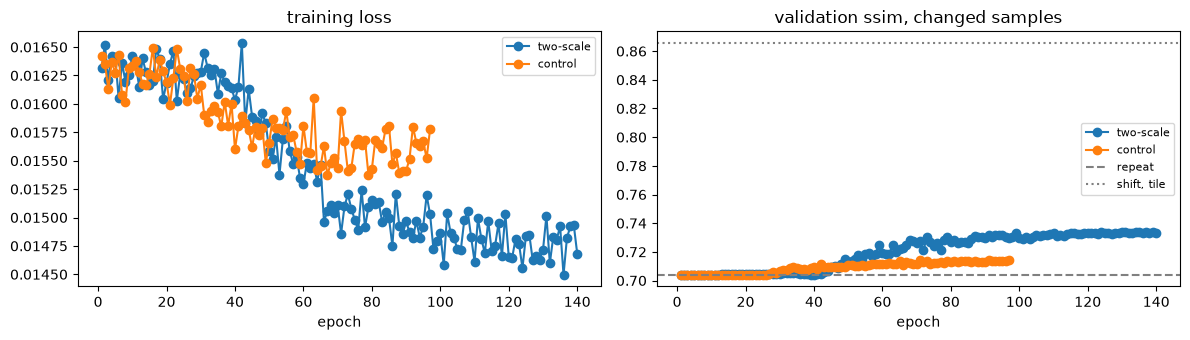

In [7]:
training.seed_everything(SEED)
histories, bests = {}, {}
for name, network in (("two-scale", model), ("control", control)):
    print(f"\n{'=' * 100}\n{name}\n{'=' * 100}")
    histories[name], bests[name] = training.train(
        network, train_loader, validation[HALO], HALO, MAX_EPOCHS, learning_rate=LEARNING_RATE,
        checkpoint=RUN_DIR / f"{name}_halo{HALO}_lr{LEARNING_RATE}.pt")
training.plot_history(histories, {name: baselines[name] for name in ("repeat", "shift, tile")})

## 5. Results

Both models against the bar, on the changed samples, the unchanged ones and all of them;
then by kind of source; then at the client's halo of 4 - the same weights, with less
context.

In [8]:
results = {**baselines,
           "two-scale": training.evaluate(model, inputs, targets, masks, trim=HALO),
           "control": training.evaluate(control, inputs, targets, masks, trim=HALO)}

for group in ("changed", "unchanged", "all"):
    print(f"\n{group}: {masks[group].sum()} samples, halo {HALO}")
    metrics.print_table({name: scores[group] for name, scores in results.items()},
                        extra=lambda name, s, g=group: f"   {s['wpsnr'] - results['repeat'][g]['wpsnr']:+6.2f} dB vs repeat")


changed: 749 samples, halo 8
                    wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
repeat              25.69    24.50    62.00    62.61     24.31   0.7040    +0.00 dB vs repeat
shift, tile         35.96    35.01    65.82    66.29     34.28   0.8657   +10.27 dB vs repeat
linear (mock)       21.94    20.75    58.29    58.72     20.60   0.6326    -3.75 dB vs repeat
two-scale           26.60    25.42    58.94    60.70     25.20   0.7340    +0.91 dB vs repeat
control             26.03    24.84    58.70    60.00     24.65   0.7144    +0.34 dB vs repeat

unchanged: 928 samples, halo 8
                    wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
repeat              84.77    84.42    93.20    93.35     83.01   0.9991    +0.00 dB vs repeat
shift, tile         83.68    83.32    92.93    93.10     81.96   0.9926    -1.09 dB vs repeat
linear (mock)       77.05    76.62    87.42    87.67     75.25   0.9916    -7.72 dB vs repeat
two-scale           69.02    68.08    87.7

In [9]:
"""By kind of source, changed samples; and at the client's halo."""

for key, label, digits in (("ssim", "SSIM-Y", 4), ("wpsnr", "wPSNR (dB)", 2)):
    print(f"{label + ', changed':<20}" + "".join(f"{kind:>10}" for kind in KINDS))
    for name, scores in results.items():
        print(f"{name:<20}" + "".join(f"{scores[f'{kind}, changed'][key]:10.{digits}f}" for kind in KINDS))
    print(f"{'samples':<20}" + "".join(f"{masks[f'{kind}, changed'].sum():10}" for kind in KINDS) + "\n")

small = webexport.TILE_HALO
x4, y4, masks4 = validation[small]
at_client = {"repeat": training.evaluate(models.Repeat(), x4, y4, masks4, trim=small),
             "shift, tile": training.evaluate(models.Shift(radius=small, block=None, fraction=FRACTION), x4, y4, masks4, trim=small),
             "two-scale": training.evaluate(model, x4, y4, masks4, trim=small),
             "control": training.evaluate(control, x4, y4, masks4, trim=small)}
print(f"{'changed samples':<20}{f'halo {HALO}':>18}{f'halo {small}':>18}")
print(f"{'':<20}" + f"{'SSIM-Y':>9}{'wPSNR':>9}" * 2)
for name, scores in at_client.items():
    wide = results[name]["changed"]
    print(f"{name:<20}{wide['ssim']:9.4f}{wide['wpsnr']:9.2f}{scores['changed']['ssim']:9.4f}{scores['changed']['wpsnr']:9.2f}")

SSIM-Y, changed           page   desktop     photo     video    cursor
repeat                  0.6723    0.7668    0.6462    0.9277    0.7170
shift, tile             0.8167    0.7650    0.9194    0.9574    0.8006
linear (mock)           0.6185    0.7154    0.5355    0.8823    0.6537
two-scale               0.6873    0.7672    0.7120    0.9364    0.7387
control                 0.6834    0.7698    0.6599    0.9311    0.7240
samples                    350        52       248        99        43

wPSNR (dB), changed       page   desktop     photo     video    cursor
repeat                   23.49     25.94     25.04     34.98     26.15
shift, tile              36.64     27.27     36.33     37.23     30.78
linear (mock)            19.77     23.06     21.00     31.40     22.25
two-scale                23.97     26.17     26.79     35.67     26.92
control                  23.85     26.02     25.46     35.17     26.25
samples                    350        52       248        99        43



changed samples                 halo 8            halo 4
                       SSIM-Y    wPSNR   SSIM-Y    wPSNR
repeat                 0.7040    25.69   0.7040    25.69
shift, tile            0.8657    35.96   0.8261    34.82
two-scale              0.7340    26.60   0.7335    26.57
control                0.7144    26.03   0.7144    26.02


### What it looks like

One changed sample of each kind. A model trained on L1 can only hedge where the future is
uncertain, and a hedge is a blur: compare its picture to repeat's, not only its score.

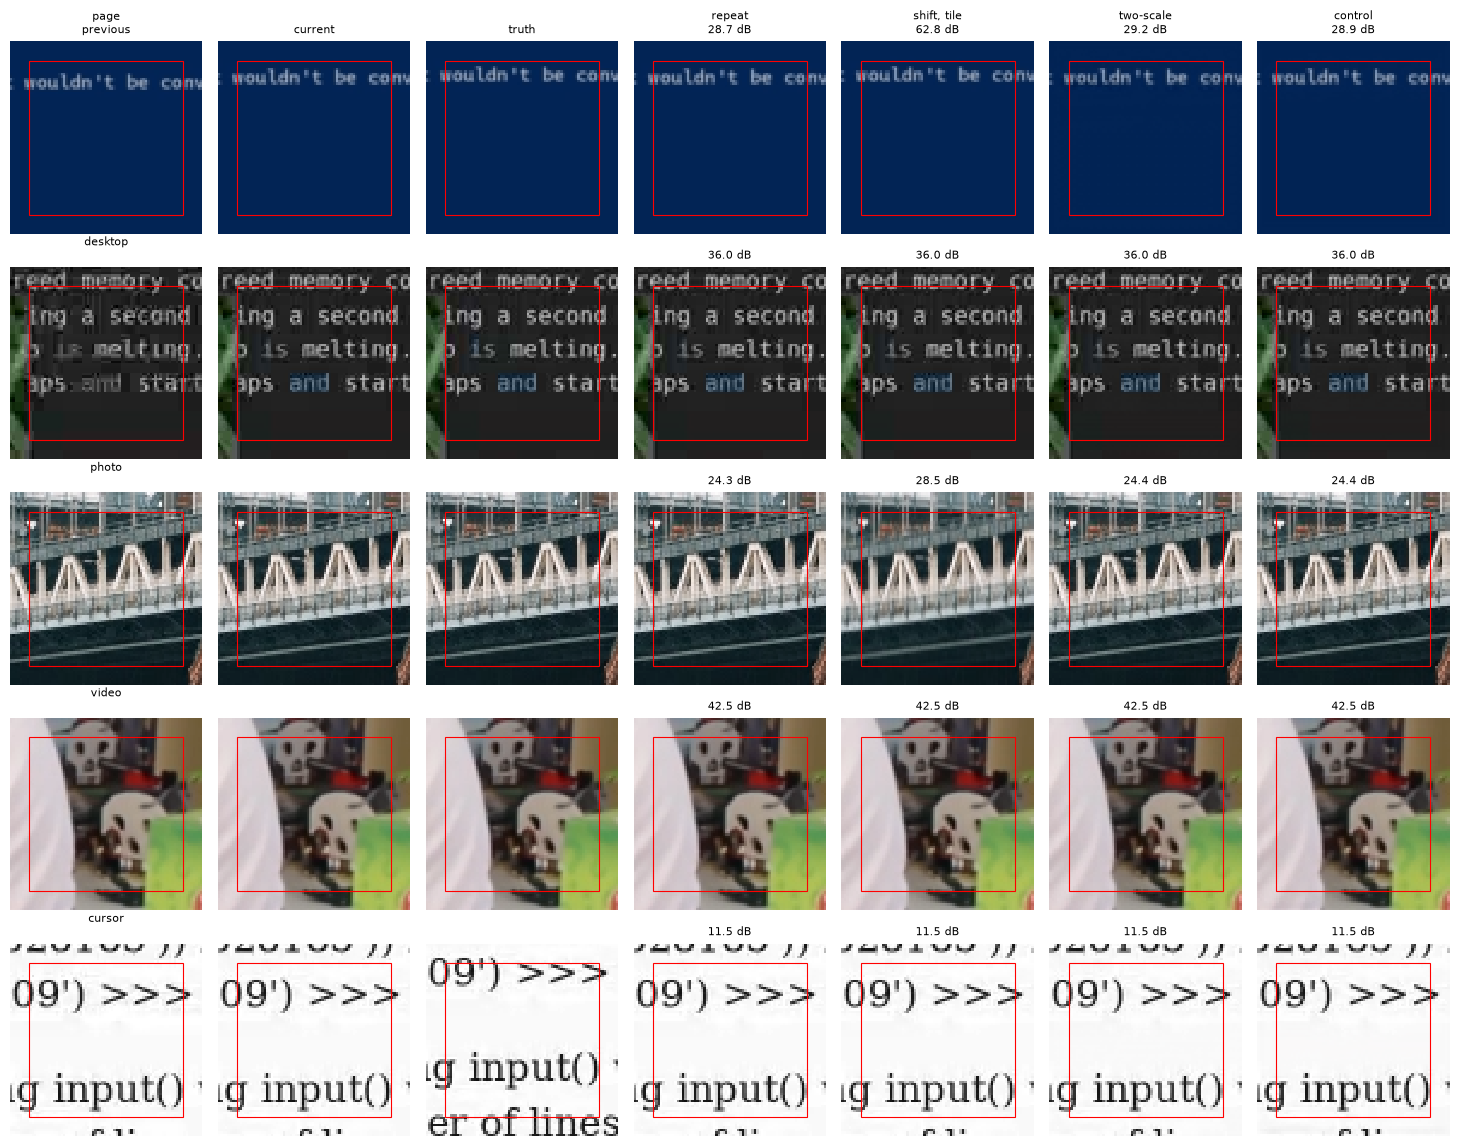

In [10]:
"""One changed sample of each kind: the inputs, the truth, and every method."""

pick_rng = np.random.default_rng(SEED)
picks = [(kind, int(pick_rng.choice(np.flatnonzero(masks[f"{kind}, changed"]))))
         for kind in KINDS if masks[f"{kind}, changed"].any()]
methods = {"repeat": models.Repeat(), "shift, tile": models.Shift(radius=HALO, block=None, fraction=FRACTION),
           "two-scale": model.eval(), "control": control.eval()}

columns = ["previous", "current", "truth", *methods]
fig, axes = plt.subplots(len(picks), len(columns), figsize=(2.1 * len(columns), 2.3 * len(picks)), squeeze=False)
for row, (kind, index) in enumerate(picks):
    sample = training.to_tensor(inputs[index:index + 1])
    truth = training.to_tensor(targets[index:index + 1])
    pictures = {"previous": sample[:, 0], "current": sample[:, 1], "truth": truth}
    with torch.no_grad():
        for name, method in methods.items():
            pictures[name] = method(sample[:, 0], sample[:, 1]).clamp(0, 1)
    for column, name in enumerate(columns):
        ax = axes[row][column]
        ax.imshow(pictures[name][0].permute(1, 2, 0).cpu().numpy(), interpolation="nearest")
        ax.add_patch(plt.Rectangle((HALO - 0.5, HALO - 0.5), manifest["core"], manifest["core"],
                                   fill=False, color="red", lw=0.8))
        title = name if row == 0 else ""
        if name in methods:
            score = metrics.wpsnr(runs.trim(pictures[name], HALO), runs.trim(truth, HALO))
            title = f"{title}\n{score:.1f} dB" if title else f"{score:.1f} dB"
        if column == 0:
            title = f"{kind}\n{title}"
        ax.set_title(title, fontsize=8)
        ax.axis("off")
fig.tight_layout()
plt.show()

### What it draws

One changed sample of each kind where the content really moves, as changes from N: what had to change between N and N+1 (the truth), and
what each method added to N. Moved content shows as a pair - the old place one colour, the
new one the other. A network that moved it would draw the same pair at full strength; one
that hedges draws a faint, smeared copy, a little at the old place and a little at the new.
The shift moves the picture itself, so its pair is the truth's wherever it found the motion.

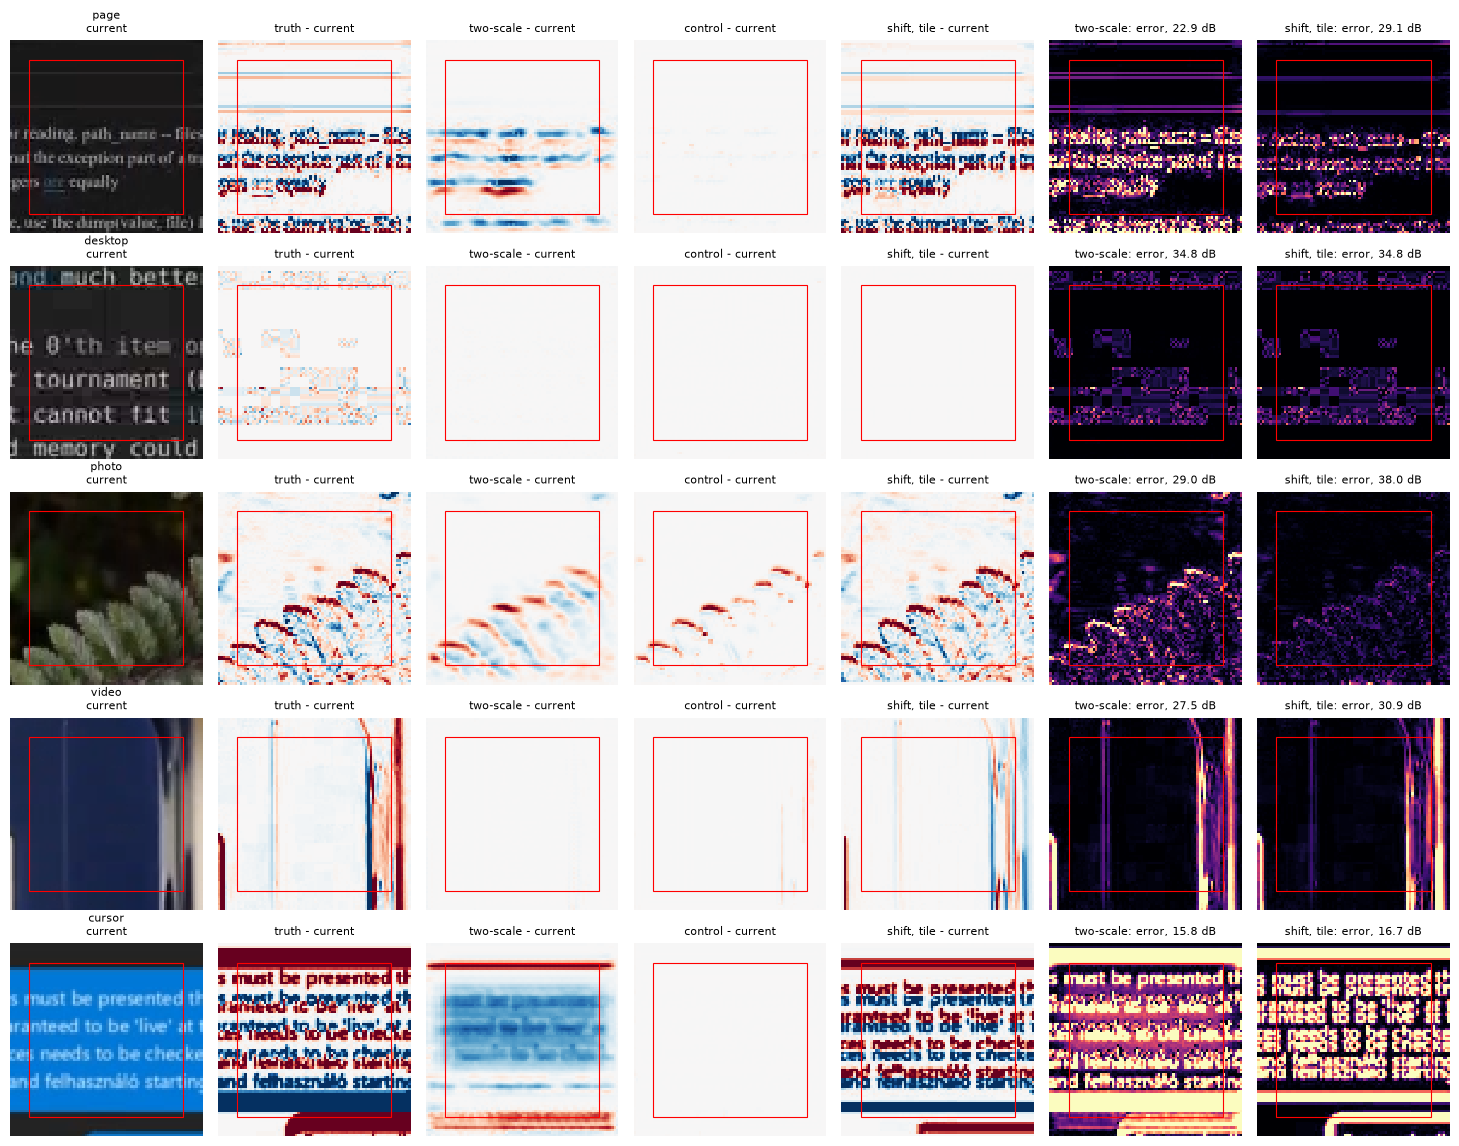

changes: red brighter, blue darker, full colour at ±48 luma levels; errors: black is right


In [10]:
"""What changed between N and N+1, and what each method added to N."""

from helpers import show

box = (HALO, HALO, manifest["core"], manifest["core"])
moving = show.moving_picks(inputs, targets, masks, KINDS, HALO, seed=SEED)   # changed samples whose content really moves
drawn = ["two-scale", "control", "shift, tile"]
columns = ["current", "truth - current", *[f"{name} - current" for name in drawn], "two-scale: error", "shift, tile: error"]
fig, axes = plt.subplots(len(moving), len(columns), figsize=(2.1 * len(columns), 2.3 * len(moving)), squeeze=False)
for row, (kind, index) in enumerate(moving):
    previous, current = training.to_tensor(inputs[index:index + 1]).unbind(1)
    truth = training.to_tensor(targets[index:index + 1])
    with torch.no_grad():
        made = {name: methods[name](previous, current).clamp(0, 1) for name in drawn}
    ax = axes[row]
    show.picture(ax[0], current, f"{kind}\ncurrent", box)
    show.change(ax[1], current, truth, columns[1], box)
    for column, name in enumerate(drawn, start=2):
        show.change(ax[column], current, made[name], f"{name} - current", box)
    for column, name in ((5, "two-scale"), (6, "shift, tile")):
        score = metrics.wpsnr(runs.trim(made[name], HALO), runs.trim(truth, HALO))
        show.error(ax[column], made[name], truth, f"{name}: error, {score:.1f} dB", box)
fig.tight_layout()
plt.show()
print(f"changes: red brighter, blue darker, full colour at ±{show.LEVELS} luma levels; errors: black is right")

## 6. Save and reload

The checkpoint holds the weights *and* everything needed to rebuild the model. We load
it into a fresh model and check it computes the same thing.

In [11]:
training.save_checkpoint(CHECKPOINT, model, architecture="TwoScale",
                         arguments={"widths": WIDTHS, "blocks": BLOCKS}, halo=HALO, context=CONTEXT, ahead=AHEAD,
                         loss="luma_chroma_l1", select=["changed", "ssim"], learning_rate=LEARNING_RATE,
                         epochs=len(histories["two-scale"]), best_epoch=bests["two-scale"]["epoch"],
                         val=results["two-scale"], val_repeat=repeat, degradation=manifest["degradation"])

checkpoint = training.load_checkpoint(CHECKPOINT)
loaded = models.TwoScale(**checkpoint["arguments"]).to(DEVICE)
loaded.load_state_dict(checkpoint["state_dict"])
training.assert_same_model(model, loaded)
print("reloaded model is identical")

saved /home/henrik/desktop-streamer-ai/src/frame_gen_extra/checkpoints/extrapolate_twoscale.pt (152 KB)
reloaded model is identical


## Export for the client

At the client's tile - a 320x180 step and a halo of 4 - with the mock's two inputs, so it can
replace `extrapolate.onnx` by being copied over it. The graph is checked against the torch
model first. It is trained at a halo of 8 and runs here at 4: "Results" shows what that
costs. A smoke test's graph is not a model, so it goes to `checkpoints/` until `PUBLISH`.

In [12]:
step_h, step_w = webexport.TILE_STEP
target = webexport.MODELS_DIR if PUBLISH else training.CHECKPOINT_DIR / "export"
info = webexport.export(loaded, f"extrapolate_{NAME}_tile{step_w}x{step_h}.onnx", webexport.TILE_INPUT,
                        label=f"two-scale {'-'.join(map(str, WIDTHS))} x{BLOCKS}", models_dir=target)
example = np.random.rand(2, 1, 3, *webexport.TILE_INPUT).astype(np.float32)
webexport.check_graph(info["path"], loaded, *example)
ms = webexport.time_graph(info["path"], webexport.TILE_INPUT)
webexport.annotate(info, cpu_ms=round(ms, 2), trained_halo=HALO, epochs=len(histories["two-scale"]))
print(webexport.summary_line(info, ms))
print(f"written to {target}")

extrapolate_twoscale_16-32x3_tile320x180.onnx         143.0 KB    1.16 ms   Addx1, Concatx2, Convx6, DepthToSpacex2, LeakyRelux5
written to /home/henrik/desktop-streamer-ai/src/frame_gen_extra/checkpoints/export
